# 08 · Creator comparison and final figures

Josh Pate vs Crain & Cone across the 5 topic pairs. Results are reported per creator because Pate has about three quarters of the comments. The notebook ends with word clouds, a table of headline numbers for the report, and an index of all figures.

In [1]:
import sys
import re
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import config

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

CREATOR_NAMES = {"pate": "Josh Pate", "crain_cone": "Crain & Cone"}
CREATOR_COLORS = {"Josh Pate": "#1f5fa8", "Crain & Cone": "#d9822b"}
PERIOD_ORDER = ["before", "announcement", "after"]

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv(config.DATA_DIR / "comments_scored.csv", keep_default_na=False,
                 parse_dates=["published_utc", "updated_utc", "video_published_utc"])
df["country"] = df["country"].replace("", np.nan)
df["creator_name"] = df["creator"].map(CREATOR_NAMES)
df.shape

(9456, 37)

In [3]:
# Main score: VADER with the sports word list (chosen with the hand labels in notebook 04).
SCORE, LABEL, SCORE_NAME = "vader_sports_compound", "vader_sports_label", "VADER + sports"

from scipy import stats
import statsmodels.formula.api as smf

def compare(a, b):
    """Welch t-test, Mann-Whitney U and Cohen's d for two score samples."""
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    t, p_t = stats.ttest_ind(b, a, equal_var=False)
    _, p_u = stats.mannwhitneyu(b, a, alternative="two-sided")
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return pd.Series({"n_a": len(a), "n_b": len(b), "mean_a": a.mean(), "mean_b": b.mean(),
                      "diff": b.mean() - a.mean(), "cohens_d": (b.mean() - a.mean()) / pooled,
                      "p_welch": p_t, "p_mannwhitney": p_u})

def neg_share(s):
    return (s == "negative").mean()

In [4]:
PAIR_NAMES = {"1_cfp_rankings_pre": "1 · CFP rankings (before)", "2_ap_poll_reaction": "2 · AP poll reaction",
              "3_expansion_reaction": "3 · Expansion reaction", "4_cfp_rankings_post": "4 · CFP rankings (after)",
              "5_week11_predictions": "5 · Week 11 predictions"}
primary = df[df["role"] == "primary"].copy()
primary["pair"] = primary["topic_pair"].map(PAIR_NAMES)
print(f"{len(primary):,} comments on the 10 primary videos")

7,283 comments on the 10 primary videos


## Overall creator comparison

In [5]:
overall = df.groupby("creator_name").agg(
    comments=("comment_id", "size"), commenters=("author_channel_id", "nunique"),
    mean_score=(SCORE, "mean"), mean_vader_std=("vader_compound", "mean"),
    mean_textblob=("tb_polarity", "mean"), mean_subjectivity=("tb_subjectivity", "mean"),
    neg_share=(LABEL, neg_share), expansion_share=("is_expansion", "mean"))
display(overall.round(3))
compare(df.loc[df["creator"] == "pate", SCORE],
        df.loc[df["creator"] == "crain_cone", SCORE]).rename(
    {"n_a": "n_pate", "n_b": "n_cc", "mean_a": "mean_pate", "mean_b": "mean_cc"}).round(4)

,comments,commenters,mean_score,mean_vader_std,mean_textblob,mean_subjectivity,neg_share,expansion_share
creator_name,,,,,,,,
Crain & Cone,2033,1095,0.135,0.146,0.087,0.379,0.307,0.047
Josh Pate,7423,3973,0.133,0.152,0.082,0.388,0.317,0.032


n_pate           7423.0000
n_cc             2033.0000
mean_pate           0.1334
mean_cc             0.1349
diff                0.0015
cohens_d            0.0029
p_welch             0.9084
p_mannwhitney       0.7789
dtype: float64

## Sentiment by creator and topic pair

In [6]:
pair_table = primary.pivot_table(index="pair", columns="creator_name", values=SCORE,
                                 aggfunc=["size", "mean"]).round(3)
pair_table.columns = [f"{stat} {name}" for stat, name in pair_table.columns]
pair_tests = pd.DataFrame({
    pair: compare(g.loc[g["creator"] == "pate", SCORE], g.loc[g["creator"] == "crain_cone", SCORE])
    for pair, g in primary.groupby("pair")}).T[["diff", "cohens_d", "p_welch"]]
pair_tests.columns = ["C&C minus Pate", "cohens_d", "p_welch"]
pair_table.join(pair_tests.round(3))

,size Crain & Cone,size Josh Pate,mean Crain & Cone,mean Josh Pate,C&C minus Pate,cohens_d,p_welch
pair,,,,,,,
1 · CFP rankings (before),503,1771,0.059,0.122,-0.064,-0.121,0.020
2 · AP poll reaction,221,1085,0.147,0.178,-0.031,-0.063,0.404
3 · Expansion reaction,448,389,0.145,0.090,0.055,0.104,0.133
4 · CFP rankings (after),275,2056,0.124,0.117,0.007,0.013,0.847
5 · Week 11 predictions,152,383,0.111,0.205,-0.094,-0.189,0.040


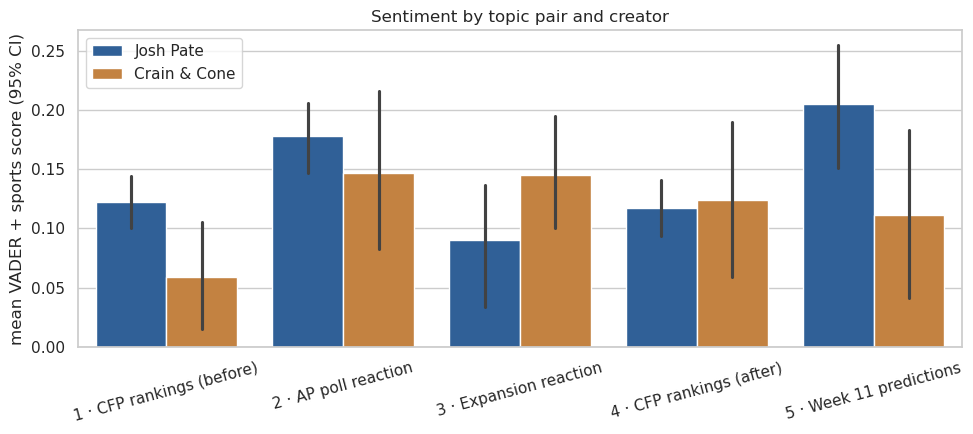

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=primary, x="pair", y=SCORE, hue="creator_name", order=list(PAIR_NAMES.values()),
            palette=CREATOR_COLORS, errorbar=("ci", 95), ax=ax)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel=None, ylabel=f"mean {SCORE_NAME} score (95% CI)", title="Sentiment by topic pair and creator")
ax.tick_params(axis="x", rotation=15)
ax.legend(title=None)
save(fig, "08_pair_sentiment.png")

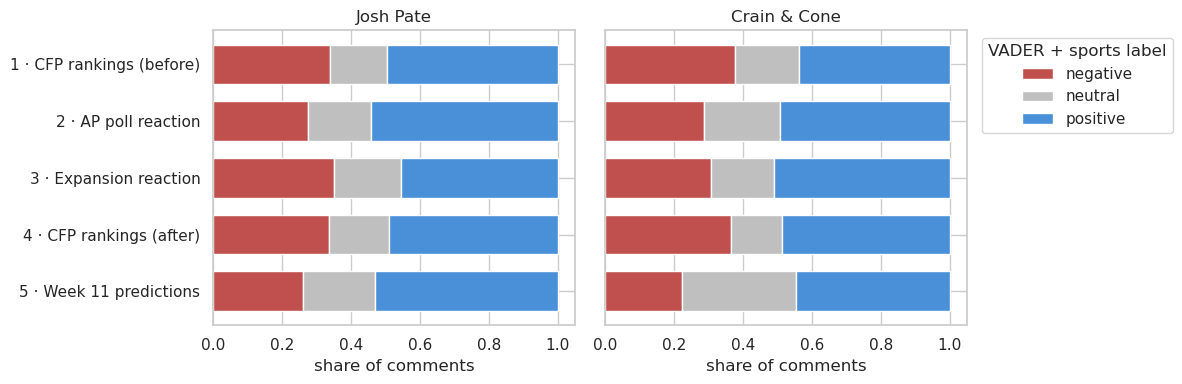

In [8]:
LABEL_ORDER = ["negative", "neutral", "positive"]
LABEL_COLORS = ["#c0504d", "#bfbfbf", "#4a90d9"]
shares = (primary.groupby(["pair", "creator_name"])[LABEL].value_counts(normalize=True)
          .unstack()[LABEL_ORDER])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, CREATOR_NAMES.values()):
    s = shares.xs(name, level="creator_name").reindex(PAIR_NAMES.values())
    s.plot.barh(stacked=True, ax=ax, color=LABEL_COLORS, legend=False, width=0.7)
    ax.set(title=name, xlabel="share of comments", ylabel=None)
    ax.invert_yaxis()
axes[1].legend(title=f"{SCORE_NAME} label", bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "08_label_shares_by_pair.png")

## Expansion-topic sentiment by creator

In [9]:
exp = df.groupby(["creator_name", "is_expansion"]).agg(
    comments=("comment_id", "size"), mean_score=(SCORE, "mean"),
    mean_vader_std=("vader_compound", "mean"), mean_textblob=("tb_polarity", "mean"),
    neg_share=(LABEL, neg_share)).round(3)
exp.index = exp.index.set_levels(["other", "expansion"], level="is_expansion")
exp

comments  mean_score  mean_vader_std  \
creator_name is_expansion                                         
Crain & Cone other             1937       0.136           0.147   
             expansion           96       0.119           0.127   
Josh Pate    other             7189       0.132           0.151   
             expansion          234       0.161           0.178   

                           mean_textblob  neg_share  
creator_name is_expansion                            
Crain & Cone other                 0.090      0.304  
             expansion             0.023      0.365  
Josh Pate    other                 0.083      0.315  
             expansion             0.057      0.376

In [10]:
exp_tests = pd.DataFrame({
    name: compare(g.loc[~g["is_expansion"], SCORE], g.loc[g["is_expansion"], SCORE])
    for name, g in df.groupby("creator_name")}).T
exp_tests.columns = ["n_other", "n_expansion", "mean_other", "mean_expansion", "diff", "cohens_d", "p_welch", "p_mannwhitney"]
exp_tests.round(3)

,n_other,n_expansion,mean_other,mean_expansion,diff,cohens_d,p_welch,p_mannwhitney
Crain & Cone,1937.0,96.0,0.136,0.119,-0.017,-0.032,0.795,0.967
Josh Pate,7189.0,234.0,0.132,0.161,0.029,0.056,0.466,0.254


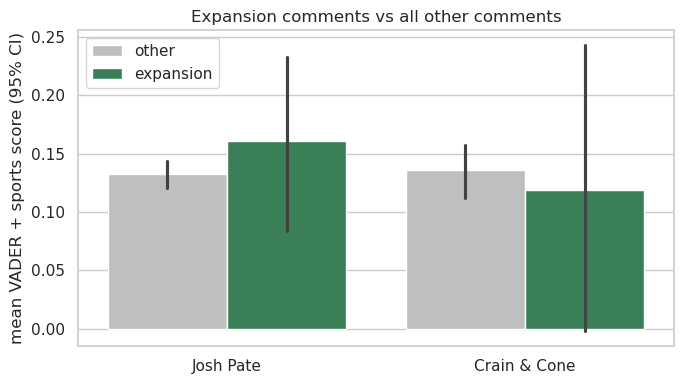

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=df.assign(topic=np.where(df["is_expansion"], "expansion", "other")), x="creator_name",
            y=SCORE, hue="topic", hue_order=["other", "expansion"],
            palette={"other": "#bfbfbf", "expansion": "#2e8b57"}, errorbar=("ci", 95), ax=ax)
ax.set(xlabel=None, ylabel=f"mean {SCORE_NAME} score (95% CI)", title="Expansion comments vs all other comments")
ax.legend(title=None)
save(fig, "08_expansion_by_creator.png")

## Word clouds

Common English stop words, the creators' names and generic football words (game, team, week, play...) are removed so that the clouds show what differs. Team names are kept.

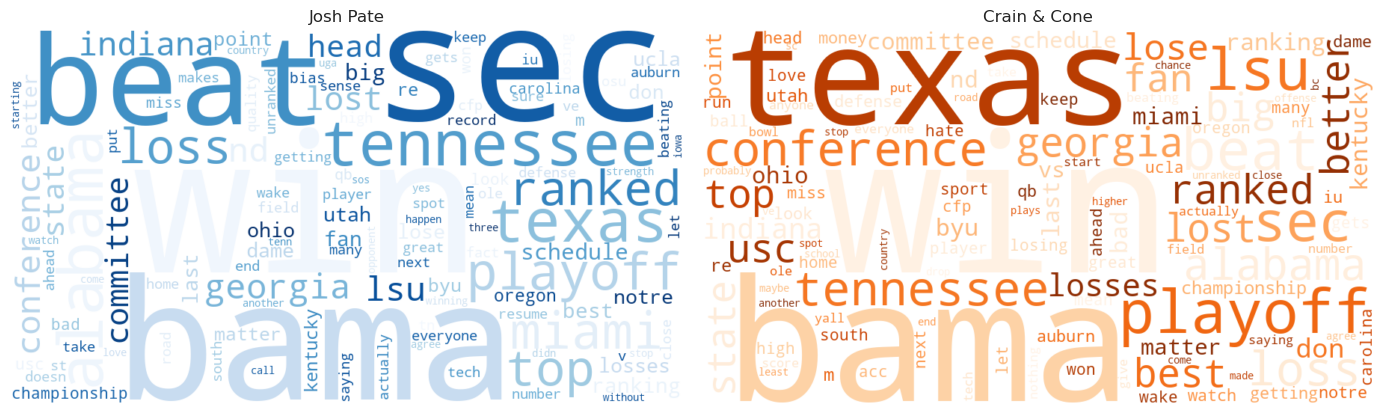

In [12]:
from wordcloud import WordCloud, STOPWORDS

EXTRA_STOP = {"josh", "pate", "crain", "cone", "game", "games", "team", "teams", "week", "play", "played",
              "playing", "will", "one", "think", "just", "like", "year", "years", "now", "get", "got", "going",
              "gonna", "know", "really", "people", "even", "still", "way", "want", "said", "say", "see", "go",
              "lol", "much", "make", "time", "good", "well", "guys", "guy", "lot", "thing", "need", "back",
              "also", "u", "s", "t", "im", "dont", "thats", "would", "could", "every", "two", "first", "right",
              "show", "always", "us", "never", "something", "can", "man", "season", "college", "football"}
STOP = STOPWORDS | EXTRA_STOP

def cloud(texts, colormap):
    text = " ".join(texts).lower()
    text = re.sub(r"https?://\S+", " ", text)
    return WordCloud(width=900, height=500, background_color="white", stopwords=STOP, colormap=colormap,
                     max_words=120, collocations=False, random_state=7).generate(text)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (creator, name), cmap in zip(axes, CREATOR_NAMES.items(), ["Blues", "Oranges"]):
    ax.imshow(cloud(df.loc[df["creator"] == creator, "text_body"], cmap), interpolation="bilinear")
    ax.set_title(name); ax.axis("off")
save(fig, "08_wordclouds_creators.png")

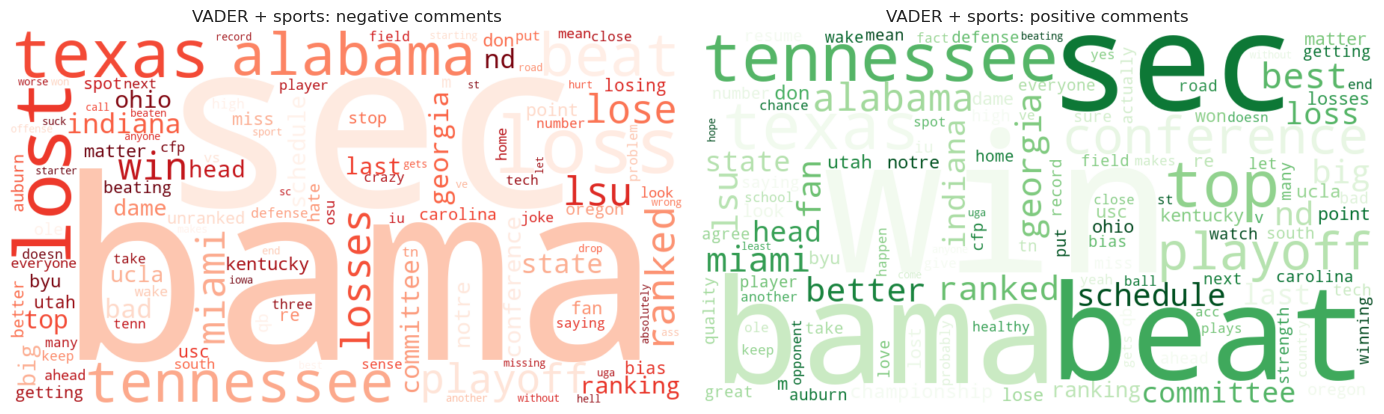

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (label, cmap) in zip(axes, [("negative", "Reds"), ("positive", "Greens")]):
    ax.imshow(cloud(df.loc[df[LABEL] == label, "text_body"], cmap), interpolation="bilinear")
    ax.set_title(f"{SCORE_NAME}: {label} comments"); ax.axis("off")
save(fig, "08_wordclouds_sentiment.png")

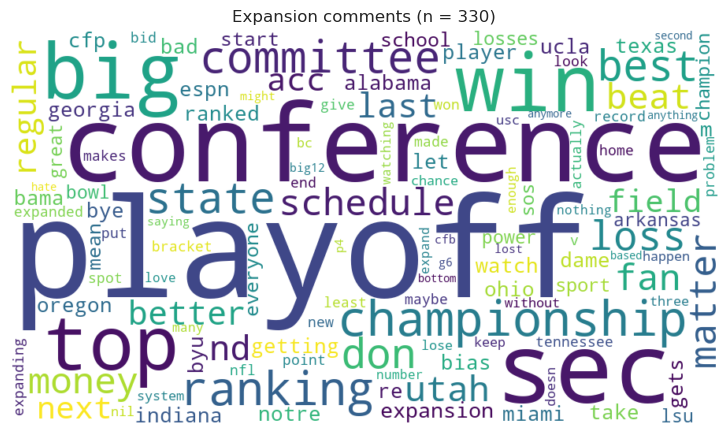

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.imshow(cloud(df.loc[df["is_expansion"], "text_body"], "viridis"), interpolation="bilinear")
ax.set_title(f"Expansion comments (n = {df['is_expansion'].sum()})"); ax.axis("off")
save(fig, "08_wordcloud_expansion.png")

## Headline numbers for the report

Pulled from the saved outputs of notebooks 02–07 so that the report and slides quote one consistent set of figures.

In [15]:
raw = pd.read_csv(config.DATA_DIR / "comments_raw.csv", usecols=["comment_id"])
event = pd.read_csv(config.DATA_DIR / "event_study_results.csv")
main = event[event["check"] == "main: VADER + sports, 10:30 ET"].set_index("group")
hand = pd.read_csv(config.DATA_DIR / "hand_labels.csv", keep_default_na=False).merge(
    df[["comment_id", "vader_label", "vader_sports_label", "tb_label"]], on="comment_id")
hand["label"] = hand["label"].str.strip().str.lower()
HAND = {c: (hand[c] == hand["label"]).mean() for c in ["vader_label", "vader_sports_label", "tb_label"]}
pre = df[df["video_published_utc"] < config.ANNOUNCE_UTC]
both = pre.groupby("video_id")["after_announce"].nunique() == 2
pre = pre[pre["video_id"].isin(both[both].index)]     # same sample as the notebook 05 within-video split

headline = pd.Series({
    "raw comments": len(raw),
    "clean comments": len(df),
    "removed in cleaning": len(raw) - len(df),
    "videos": df["video_id"].nunique(),
    "commenters": df["author_channel_id"].nunique(),
    "share Josh Pate": (df["creator"] == "pate").mean(),
    "VADER + sports positive share": (df[LABEL] == "positive").mean(),
    "VADER + sports negative share": (df[LABEL] == "negative").mean(),
    "standard VADER positive share": (df["vader_label"] == "positive").mean(),
    "standard VADER negative share": (df["vader_label"] == "negative").mean(),
    "TextBlob positive share": (df["tb_label"] == "positive").mean(),
    "TextBlob negative share": (df["tb_label"] == "negative").mean(),
    "hand-label accuracy, VADER + sports": HAND["vader_sports_label"],
    "hand-label accuracy, standard VADER": HAND["vader_label"],
    "hand-label accuracy, TextBlob": HAND["tb_label"],
    "expansion comments": int(df["is_expansion"].sum()),
    "within-video split: comments before": int((~pre["after_announce"]).sum()),
    "within-video split: comments after": int(pre["after_announce"].sum()),
    "event coef (all, controlled)": main.loc["All", "coef_after"],
    "event p (all, controlled)": main.loc["All", "p"],
    "event coef Josh Pate": main.loc["Josh Pate", "coef_after"],
    "event coef Crain & Cone": main.loc["Crain & Cone", "coef_after"],
})
headline.to_frame("value").to_csv(config.DATA_DIR / "headline_numbers.csv")
headline.map(lambda v: f"{v:,.3f}" if isinstance(v, float) and abs(v) < 1 else f"{v:,.0f}").to_frame("value")

,value
raw comments,"9,561"
clean comments,"9,456"
removed in cleaning,105
videos,18
commenters,"4,852"
share Josh Pate,0.785
VADER + sports positive share,0.498
VADER + sports negative share,0.315
standard VADER positive share,0.510
standard VADER negative share,0.297


## Figure index

In [16]:
FIGURE_USE = {
    "02_comment_age_hist.png": "cleaning: comment age and the outdated cutoff",
    "03_creator_share_pie.png": "data: comments per creator",
    "03_comments_per_pair.png": "data: comments per topic pair",
    "03_comments_per_commenter.png": "data: commenter concentration",
    "03_length_boxplots.png": "data: comment length by creator",
    "03_length_hist.png": "data: comment length distribution",
    "03_volume_over_time.png": "data: comment volume over time",
    "04_score_distributions.png": "method: VADER / TextBlob score distributions",
    "04_vader_vs_textblob_scatter.png": "method: VADER vs TextBlob agreement",
    "04_failure_patterns.png": "method: tool accuracy on direct vs indirect negativity",
    "05_period_means.png": "result: sentiment by video period",
    "05_within_video_split.png": "result (main): before vs after within videos",
    "05_time_series.png": "result: volume and sentiment over time",
    "05_event_window.png": "result: ±48 h event window",
    "06_top_teams.png": "result: most-mentioned teams",
    "06_conference_sentiment.png": "result: sentiment by conference",
    "06_state_tile_map.png": "result: inferred state map",
    "07_top_emoji.png": "result: most-used emoji",
    "07_emotion_groups.png": "result: emoji emotion groups",
    "07_groups_by_creator.png": "result: emoji groups by creator",
    "07_emoji_effect_on_vader.png": "method: how emoji move VADER",
    "08_pair_sentiment.png": "result: creator comparison by topic pair",
    "08_label_shares_by_pair.png": "result: label shares by pair",
    "08_expansion_by_creator.png": "result: expansion vs other comments",
    "08_wordclouds_creators.png": "visual: word clouds by creator",
    "08_wordclouds_sentiment.png": "visual: negative vs positive word clouds",
    "08_wordcloud_expansion.png": "visual: expansion word cloud",
}
files = sorted(p.name for p in FIG_DIR.glob("*.png"))
index = pd.DataFrame({"figure": files, "use": [FIGURE_USE.get(f, "") for f in files]})
missing = set(FIGURE_USE) - set(files)
print(f"{len(files)} figures; missing from disk: {sorted(missing) or 'none'}")
index

27 figures; missing from disk: none


,figure,use
0,02_comment_age_hist.png,cleaning: comment age and the outdated cutoff
1,03_comments_per_commenter.png,data: commenter concentration
2,03_comments_per_pair.png,data: comments per topic pair
3,03_creator_share_pie.png,data: comments per creator
4,03_length_boxplots.png,data: comment length by creator
5,03_length_hist.png,data: comment length distribution
6,03_volume_over_time.png,data: comment volume over time
7,04_failure_patterns.png,method: tool accuracy on direct vs indirect negativity
8,04_score_distributions.png,method: VADER / TextBlob score distributions
9,04_vader_vs_textblob_scatter.png,method: VADER vs TextBlob agreement
